# Clase 2 · Camino hacia GRPO

Recorrido docente de **REINFORCE → PPO (ejemplo de loss) → RLOO → GRPO**. Lectura sugerida: [Cameron R. Wolfe](https://cameronrwolfe.substack.com/p/llm-rl). Fórmulas contrastadas con [PPO](https://arxiv.org/abs/1707.06347), [RLOO](https://arxiv.org/abs/2402.14740) y [DeepSeekMath](https://arxiv.org/abs/2402.03300).

**Modelo ejecutable:** GRU autoregresiva de 13.923 parámetros, vocabulario cerrado y tres contextos. Primero SFT, después ajuste por RL. No es un LLM preentrenado ni reproduce capacidades de razonamiento de modelos grandes. CPU funciona; CUDA/Orin queda pendiente. La demo no descarga pesos.

**Objetivos:** reconocer estado/acción/retorno; construir ventajas; distinguir política actual, vieja y referencia; interpretar reward, KL, diversidad y evaluación humana.

Ejecutar desde un kernel nuevo. PyTorch y Matplotlib; instalar según el dispositivo (ver JETSON.md). Las preferencias por defecto son **simuladas**; configurar un archivo etiquetado por personas para la ruta humana.

**Hilo conductor:** cada etapa introduce una pieza necesaria para GRPO. REINFORCE explica el update; baseline/ventaja introduce la comparación; PPO aporta ratios y clipping; RLOO ayuda a entender grupos; GRPO reúne una ventaja relativa con el surrogate clipped. No es una cronología de reemplazos. Ver [camino hacia GRPO](CAMINO_A_GRPO.md) y su ejemplo continuo. SFT/RM pueden prepararse antes para concentrar la práctica en el update.


In [1]:
from pathlib import Path
import sys, copy, json, time
import torch
import matplotlib.pyplot as plt
candidates = [Path.cwd(), Path.cwd() / '2026' / 'clase2', Path.cwd() / 'clase2']
HERE = next((p for p in candidates if (p / 'llm_policy_gradients.py').exists()), None)
if HERE is None:
    raise RuntimeError('Abrir desde la raíz del repo o 2026/clase2')
sys.path.insert(0, str(HERE))
import mini_rlhf as tiny
import llm_policy_gradients as pg
torch.set_num_threads(2)
DEVICE = torch.device('cpu')  # Cambiar a cuda solo después del diagnóstico.
PREFERENCE_FILE = None  # Path a preferencias_humanas.json, etiquetadas con mini_rlhf.py.
REWARD_SOURCE = 'learned'  # learned: reward model; verifier: contrato de formato.
STEPS, GROUP_SIZE, BETA, GRPO_UPDATES = 60, 8, .1, 3
OUTPUT = HERE / 'outputs' / 'policy_gradients_notebook'
print('Device:', DEVICE, '| PyTorch:', torch.__version__)

Device: cpu | PyTorch: 2.9.0


## 1. Un generador como política

Para prompt $x$, estado $s_t=(x,y_{<t})$, acción $a_t=y_t$, transición: anexar el token. La distribución de siguiente token es $\pi_\theta(a_t|s_t)$ y la trayectoria es la respuesta hasta EOS o el presupuesto. Con recompensa final y $\gamma=1$, el retorno de cada token incluye el resultado completo.

También podemos considerar toda la respuesta como una acción de un bandido contextual. Es una abstracción útil para el REINFORCE de secuencia. No convierte automáticamente la generación con herramientas en un bandido: allí intervienen observaciones externas.

**Pregunta:** en Q-learning maximizábamos valores de acciones; aquí ajustamos directamente su probabilidad. ¿Cuál es la acción en cada uno?

In [2]:
contexts, labels = tiny.batch_rows([{'context': 'saludo', 'text': 'hola puedo ayudarte'}], DEVICE)
print('Prompt:', tiny.PROMPTS['saludo'])
print('Acciones:', [tiny.VOCAB[i] for i in labels[0].tolist()])
print('Máscara:', pg.completion_mask(labels)[0].tolist())
assert pg.completion_mask(labels).sum() == 4  # Tres palabras + EOS.

Prompt: Hola, ¿podemos empezar?
Acciones: ['hola', 'puedo', 'ayudarte', '<eos>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']
Máscara: [True, True, True, True, False, False, False, False, False, False]


## 2. SFT y origen de la recompensa

El SFT imita 18 frases. El reward model aprende una comparación: $P(A\succ B)=\sigma(r_\phi(x,A)-r_\phi(x,B))$. Tiene 1.089 parámetros y usa bolsa de palabras: no entiende negaciones ni orden.

Para recoger feedback: `python mini_rlhf.py --export-pairs preferencias_humanas.json`, luego `--label-pairs preferencias_humanas.json`. El archivo conserva `human` y empates/skips. Hay 18 pares de train y seis de validación; comparten contextos y frases, así que no son una prueba de generalización semántica. La evaluación de textos nuevos se realiza aparte.

**Dos ejes diferentes:** `RLHF/RLVR` describe la señal; `REINFORCE/PPO/GRPO` describe cómo actualizamos. GRPO admite tanto una recompensa aprendida de personas como un verificador.

In [3]:
started = time.perf_counter()
model, reference, rm, center, scale, preparation = pg.prepare(DEVICE, PREFERENCE_FILE)
print('Preferencias:', preparation['feedback_source'])
print('Parámetros política / recompensa:', sum(p.numel() for p in model.parameters()), sum(p.numel() for p in rm.parameters()))
print('Accuracy en seis pares reservados:', preparation['preference_validation_accuracy'])
assert all(not p.requires_grad for p in reference.parameters())
assert all(not p.requires_grad for p in rm.parameters())

Preferencias: SIMULATED
Parámetros política / recompensa: 13923 1089
Accuracy en seis pares reservados: 1.0


## 3. REINFORCE: subir probabilidades según el retorno

Usamos $J=\mathbb E_{y\sim\pi_\theta}[r(x,y)]-\beta D_{KL}(\pi_\theta\Vert\pi_{ref})$ y el estimador de secuencia $-\text{mean}[(R_i-b)\sum_t\log\pi_\theta(y_{i,t}|s_{i,t})]$. En esta ruta $R_i$ incluye recompensa y KL muestreada, ambas detenidas para la actualización; el baseline móvil proviene de batches anteriores.

Un baseline que depende de la acción rompe la justificación de insesgadez. Restar la media del batch que incluye la propia muestra no es lo mismo que leave-one-out.

### RLOO y GRPO: calcular antes de entrenar

RLOO: $A_i=R_i-\frac{1}{G-1}\sum_{j\ne i}R_j$. GRPO: $A_i=(r_i-\bar r)/(\mathrm{std}_{pop}(r)+\epsilon)$. Comparamos respuestas **al mismo prompt**. En nuestra GRPO la KL se agrega a la loss, por fuera del reward normalizado.

In [4]:
rewards = torch.tensor([[0., 0., 1., 1.], [1., 1., 1., 1.]])
print('Rewards por prompt:\n', rewards)
print('Ventajas RLOO:\n', pg.group_advantages(rewards, 'rloo'))
print('Ventajas GRPO:\n', pg.group_advantages(rewards, 'grpo'))
assert torch.equal(pg.group_advantages(rewards, 'grpo')[1], torch.zeros(4))
# Sin diferencia de recompensa, el gradiente de tarea es cero. La KL puede seguir actuando.

Rewards por prompt:
 tensor([[0., 0., 1., 1.],
        [1., 1., 1., 1.]])
Ventajas RLOO:
 tensor([[-0.6667, -0.6667,  0.6667,  0.6667],
        [ 0.0000,  0.0000,  0.0000,  0.0000]])
Ventajas GRPO:
 tensor([[-1., -1.,  1.,  1.],
        [ 0.,  0.,  0.,  0.]])


## 4. PPO: critic, reutilización y clipping

El critic estima retorno esperado desde el estado; el reward model puntúa la respuesta. Son funciones diferentes. PPO suele estimar ventajas con critic/GAE, guarda logprobs de $\pi_{old}$ y reutiliza el rollout.

$\rho_t=\exp(\log\pi_\theta-\log\pi_{old})$; objetivo local $\min(\rho_t A_t,\mathrm{clip}(\rho_t,1-\epsilon,1+\epsilon)A_t)$. El clipping es **direccional**: para ventaja positiva se activa arriba, para negativa abajo. No congela siempre el gradiente fuera del intervalo ni garantiza una cota estricta de KL.

Aquí mostramos ese objetivo con números; **no entrenamos PPO ni un critic**. GRPO reutiliza el objetivo con ventajas relativas al grupo.

In [5]:
ratio = torch.tensor([1.5, .5, 1.5, .5], requires_grad=True)
advantage = torch.tensor([1., 1., -1., -1.])
surrogate, active = pg.clipped_surrogate(ratio, advantage)
(-surrogate.sum()).backward()
for r, a, value, clipped, grad in zip(ratio.detach().tolist(), advantage.tolist(), surrogate.detach().tolist(), active.tolist(), ratio.grad.tolist()):
    print(f'ratio={r}, A={a:+.0f}, objetivo={value:+.2f}, clip activo={clipped}, grad loss={grad:+.1f}')
assert active.tolist() == [True, False, False, True]
assert ratio.grad.tolist() == [0., -1., 1., 0.]

ratio=1.5, A=+1, objetivo=+1.20, clip activo=True, grad loss=+0.0
ratio=0.5, A=+1, objetivo=+0.50, clip activo=False, grad loss=-1.0
ratio=1.5, A=-1, objetivo=-1.50, clip activo=False, grad loss=+1.0
ratio=0.5, A=-1, objetivo=-0.80, clip activo=True, grad loss=+0.0


## 5. Referencia, vieja y actual; KL y máscaras

`ref`: checkpoint SFT congelado durante toda la corrida. `old`: política al generar el último batch, logprobs congeladas durante sus actualizaciones. `current`: parámetros que cambian. Al iniciar un rollout `old=current`; después de actualizar divergen. `old` y `ref` coinciden solo al inicio.

En secuencia excluimos prompt y PAD y **contamos EOS**. Aquí el prompt entra como contexto, no como token predicho. Teacher forcing desplaza BOS/respuesta una posición para evaluar cada acción.

La media de $k_1=\log\pi-\log\pi_{ref}$ puede ser negativa en pocas muestras. $k_3=\exp(\log\pi_{ref}-\log\pi)-(\log\pi_{ref}-\log\pi)-1$ es no negativo por acción. Su expectativa da la KL con acciones de la distribución actual; al reutilizar rollouts viejos la loss sigue siendo un surrogate. No confundir esa estimación con la KL exacta de todo el vocabulario.

In [6]:
p, q = torch.tensor([.8, .2]), torch.tensor([.5, .5])
k1 = p.log() - q.log()
k3 = pg.sampled_k3(p.log(), q.log())
print('k1 por acción:', k1.tolist(), '| KL exacta:', (p*k1).sum().item())
print('k3 por acción:', k3.tolist(), '| esperanza con p:', (p*k3).sum().item())
assert torch.allclose((p*k1).sum(), (p*k3).sum())
with torch.no_grad():
    generated, sampled_lp, _, _ = tiny.sample(model, reference, contexts)
    scored_lp, _, mask = pg.token_statistics(model, contexts, generated)
assert torch.allclose(scored_lp.sum(1), sampled_lp, atol=2e-5)
print('Logprob del muestreo coincide con teacher forcing; EOS/PAD verificados.')

k1 por acción: [0.4700036644935608, -0.9162907600402832] | KL exacta: 0.19274477660655975
k3 por acción: [0.0950036346912384, 0.5837093591690063] | esperanza con p: 0.19274479150772095
Logprob del muestreo coincide con teacher forcing; EOS/PAD verificados.


## 6. Ajustar las políticas desde el mismo SFT

Cada método parte de una copia del mismo checkpoint, usa 60 batches de 24 respuestas (tres prompts × ocho muestras) y la misma semilla inicial. Después las muestras divergen con las políticas. REINFORCE/RLOO hacen una actualización por batch; GRPO hace tres. **No es un ranking justo de algoritmos:** el número de actualizaciones y sus objetivos difieren. Se registran ambos presupuestos y tiempo.

GRPO ejecuta ventajas sin critic, ratios por token, clipping, KL $k_3$ diferenciable y media por respuesta de la formulación original. No implementa DAPO ni Dr. GRPO. Se mide entropía, longitudes, fracción de grupos con recompensa idéntica y clipping activo.

In [7]:
result, policies = pg.compare(model, reference, rm, center, scale, DEVICE,
                              steps=STEPS, group_size=GROUP_SIZE, beta=BETA,
                              updates=GRPO_UPDATES, reward_source=REWARD_SOURCE)
result['preparation'] = preparation
pg.save(result, policies, reference, rm, center, scale, OUTPUT)
print('Segundos del pipeline en este equipo:', round(time.perf_counter() - started, 2))
print('Recompensa usada:', REWARD_SOURCE, '| origen preferencias:', preparation['feedback_source'])
print('Método | proxy | contrato | KL secuencia | respuestas distintas | updates')
before = result['before']
print('SFT', *(round(before[k], 3) for k in ['reward_proxy','contract_pass_rate','sampled_sequence_kl','unique_text_fraction']))
for method, run in result['runs'].items():
    after = run['after']
    print(method, *(round(after[k], 3) for k in ['reward_proxy','contract_pass_rate','sampled_sequence_kl','unique_text_fraction']), run['optimizer_updates'])

Segundos del pipeline en este equipo: 3.76
Recompensa usada: learned | origen preferencias: SIMULATED
Método | proxy | contrato | KL secuencia | respuestas distintas | updates
SFT -0.195 0.322 0.0 0.089
reinforce 1.172 1.0 1.641 0.022 60
rloo 1.163 0.994 1.62 0.028 60
grpo 1.183 0.917 3.54 0.061 180


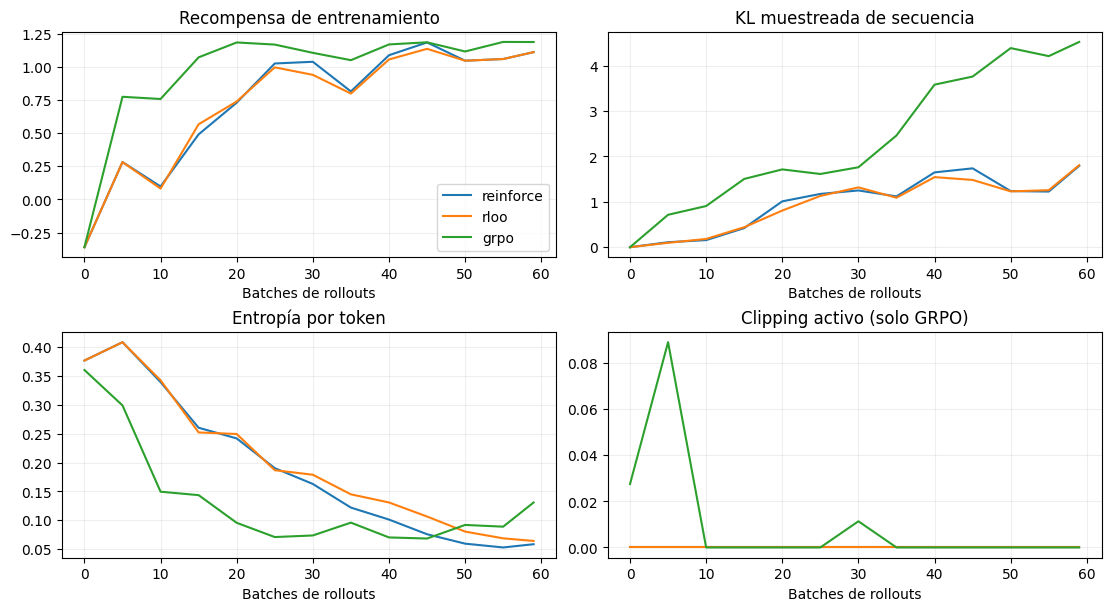

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), constrained_layout=True)
for ax, key, title in zip(axes.flat,
        ['reward', 'sampled_sequence_kl', 'entropy_per_token', 'active_clip_fraction'],
        ['Recompensa de entrenamiento', 'KL muestreada de secuencia', 'Entropía por token', 'Clipping activo (solo GRPO)']):
    for method, run in result['runs'].items():
        h = run['history']
        ax.plot([v['step'] for v in h], [v[key] for v in h], label=method)
    ax.set(title=title, xlabel='Batches de rollouts'); ax.grid(alpha=.2)
axes[0,0].legend()
plt.show()

## 7. Cambiar la recompensa manteniendo GRPO

El verificador comprueba un contrato: prefijo `hola`, `claro` o `de nada` según contexto; 1–6 palabras sin repetición; finalización EOS. Es **RLVR de formato**, no un test de razonamiento ni de utilidad. La frase “claro vete” puede cumplirlo y ser mala. No llamarlo RLHF.

Ejecutamos otra GRPO desde SFT con ese verificador y medimos también el reward model anterior. ¿Suben ambos? ¿Qué queda sin medir?

In [9]:
verifier_policy = copy.deepcopy(model)
verifier_history = pg.train_policy(verifier_policy, reference, rm, center, scale, DEVICE, 'grpo',
                                  steps=STEPS, group_size=GROUP_SIZE, beta=BETA,
                                  updates=GRPO_UPDATES, reward_source='verifier')
verifier_after = pg.evaluate(verifier_policy, reference, rm, center, scale, DEVICE)
print('Contrato antes / después:', result['before']['contract_pass_rate'], verifier_after['contract_pass_rate'])
print('Proxy antes / después:', result['before']['reward_proxy'], verifier_after['reward_proxy'])
print('Grupos de igual recompensa al final:', verifier_history[-1]['equal_reward_group_fraction'])
for row in verifier_after['samples'][:9]:
    print(row['context'], '→', row['text'])
verifier_result = {'config': {**result['config'], 'reward_source': 'verifier'},
                   'before': result['before'], 'after': verifier_after, 'history': verifier_history,
                   'human_quality_verified': False}
(OUTPUT / 'verifier_metrics.json').write_text(json.dumps(verifier_result, ensure_ascii=False, indent=2), encoding="utf-8")
# Guardar también este ajuste para no repetirlo durante clase.
torch.save({'policy': {k: v.detach().cpu() for k,v in verifier_policy.state_dict().items()},
            'config': verifier_result['config']}, str(OUTPUT / 'verifier_policy.pt'))

Contrato antes / después: 0.3222222328186035 0.9722222089767456
Proxy antes / después: -0.19476188719272614 1.045777440071106
Grupos de igual recompensa al final: 0.6666666865348816
saludo → hola que necesitas
ayuda → claro puedo ayudarte
gracias → de nada seguimos cuando quieras
saludo → hola que necesitas
ayuda → claro puedo ayudarte
gracias → de nada
saludo → hola que necesitas
ayuda → claro puedo ayudarte
gracias → de nada


## 8. Evaluación y discusión

Abrir `outputs/policy_gradients_notebook/blind_grpo/evaluacion_ciega.json`. Otro grupo compara A/B sin ver `clave_evaluacion_docente.json`. Registrar razones, empates/skips y preferencias por contexto antes de revelar origen. No ajustar hiperparámetros con ese test.

Los 180 textos por política repiten tres contextos; son muestras nuevas, **no prompts fuera de distribución**. Una semilla no determina superioridad. Más proxy o cumplimiento no demuestra calidad humana. Revisar respuestas concretas y pérdida de diversidad.

**Actividad con IA opcional:** evaluar la afirmación “GRPO es RLHF sin reward model”. Entregar una clasificación por señal y por optimizador, y un contraejemplo obtenido aquí. Sin IA, analizar la misma afirmación proporcionada por el docente.

**Ablaciones para grupos:** beta=0/.1/.5; G=2/8; una/tres actualizaciones GRPO; recompensa constante; media por respuesta versus media global de tokens. Cambiar una variable por vez, registrar predicción y presupuesto. En grupos de recompensa constante desaparece el término de tarea, pero la KL puede producir actualización si la política difiere de referencia.

**Para leer después:** DPO usa pares y una referencia con un objetivo directo; DAPO y Dr. GRPO estudian detalles de muestreo/normalización/longitud, GSPO cambia el ratio. No prometer mejoras universales. [DPO](https://arxiv.org/abs/2305.18290), [DAPO](https://arxiv.org/abs/2503.14476), [Dr. GRPO](https://arxiv.org/abs/2503.20783), [GSPO](https://arxiv.org/abs/2507.18071).

**Orin Nano 8 GB:** prueba remota aplazada a pedido de Juan, equipo desconectado. El notebook pequeño queda como demostración de mecanismos; la extensión con LLM preentrenado sigue pendiente de implementación y medición (ORIN_LLM_PLAN.md).